# 4. Модели и сравнение на valid

Роли выборок по `docs/plan.md`: на train - обучение и подбор гиперпараметров 5-fold CV, на valid - только
сравнение подходов, test здесь не загружается. Подбор и обучение - `python -m src.models` (около 15 минут),
этот ноутбук читает из `artifacts/` выбранные параметры и скоры на valid.

Три модели на LightGBM:
- модель отклика: P(target = 1 | treatment = 1, X), обучена только на treatment-части train, скор - эта вероятность;
- T-learner: модели на treatment- и control-частях train, uplift = p_t - p_c;
- трансформация классов: Z = Y·T + (1 - Y)(1 - T), uplift = 2·P(Z = 1 | X) - 1.

Модель отклика и treatment-модель T-learner - одна и та же модель: те же данные, тот же подбор, тот же seed.
Разница только в скоре: отклик ранжирует по p_t, T-learner - по p_t - p_c.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, models, plots, stats, uplift

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plots.setup()
ART = models.ARTIFACTS
MODELS = ["response", "t_learner", "class_transformation"]
UPLIFT_MODELS = ["t_learner", "class_transformation"]
KS = (0.1, 0.2, 0.3)

## Подбор гиперпараметров

Сетка из 18 комбинаций, критерий - средний по 5 фолдам logloss в лучшей итерации ранней остановки, число деревьев -
медиана лучших итераций. Подбор по logloss оптимизирует точность предсказания отклика, а не качество uplift:
у T-learner каждая модель хорошо предсказывает покупку в своей группе, но это не гарантирует, что их разность
хорошо ранжирует по эффекту.

In [2]:
best = json.loads((ART / "best_params.json").read_text())
pd.DataFrame(best).T[["num_leaves", "min_child_samples", "learning_rate", "n_trees", "cv_logloss"]]

,num_leaves,min_child_samples,learning_rate,n_trees,cv_logloss
response,15.0,100.0,0.03,261.0,0.534209
t_control,15.0,400.0,0.03,240.0,0.547334
class_transformation,15.0,400.0,0.10,16.0,0.692084
t_treatment,15.0,100.0,0.03,261.0,0.534209


In [3]:
cv = pd.read_csv(ART / "cv_results.csv")
cv.groupby("model").cv_logloss.agg(["min", "max"]).assign(spread=lambda d: d["max"] - d["min"])

,min,max,spread
model,,,
class_transformation,0.692084,0.692470,0.000386
response,0.534209,0.536369,0.002160
t_control,0.547334,0.548980,0.001646


In [4]:
_, y_tr, t_tr = models.load("train")
p = t_tr.mean()
print(f"доля treatment в train: {p:.4f}; веса были бы 0,5/p = {0.5 / p:.4f} и 0,5/(1-p) = {0.5 / (1 - p):.4f}")
pz = models.class_target(y_tr, t_tr).mean()
print(f"доля Z = 1 в train: {pz:.4f}; logloss константы: {-(pz * np.log(pz) + (1 - pz) * np.log(1 - pz)):.4f}")

доля treatment в train: 0.4998; веса были бы 0,5/p = 1.0004 и 0,5/(1-p) = 0.9996
доля Z = 1 в train: 0.5166; logloss константы: 0.6926


У всех моделей лучшая комбинация - 15 листьев. Модель отклика (она же treatment-модель T-learner): 261 дерево,
logloss 0,5342. Control-модель T-learner: 240 деревьев, 0,5473. Разброс logloss по всей сетке маленький -
от 0,0004 до 0,0022, то есть выбор гиперпараметров здесь мало что меняет.

Трансформация классов: 16 деревьев при learning_rate 0,1 и logloss 0,6921 - почти как у константы (0,6926).
Сигнал uplift слабый: Z почти не предсказывается, и ранняя остановка по logloss обрывает обучение рано.
Это и есть оговорка про подбор по logloss: модель выбрана по точности предсказания Z, а не по Qini.

Доля treatment в train 0,4998: веса для трансформации классов были бы 1,0004 и 0,9996, поэтому обучаю без весов.

## Метрики на valid

Скоры моделей с seed 42 - те, что пойдут на test. Интервалы - парный бутстреп на valid: скоры фиксированы,
клиентов пересэмплирую отдельно внутри treatment и control, 1 000 повторов, все модели на одной выборке.
Случайная рассылка: uplift@k = ATE_valid при любом k, Qini - распределение по 1 000 случайных перестановок скоров.
Дополнительные покупатели на 1 000 сообщений = uplift@k x 1000.

In [5]:
X_valid, y, t = models.load("valid")
scores_all = pd.read_parquet(ART / "valid_scores.parquet")
scores_all = scores_all.pivot_table(index=["client_id"], columns=["model", "seed"], values="score")
scores_all = scores_all.loc[X_valid.index]
scores = {m: scores_all[(m, config.SEED)].to_numpy() for m in MODELS}
ate_valid = y[t == 1].mean() - y[t == 0].mean()
print(f"valid: {len(y)} клиентов, treatment {int(t.sum())}, control {int((1 - t).sum())}, ATE_valid = {ate_valid * 100:.2f} п.п.")

valid: 40008 клиентов, treatment 19996, control 20012, ATE_valid = 3.32 п.п.


In [6]:
point = pd.DataFrame({m: uplift.metrics(y, t, scores[m], KS) for m in MODELS}).T
boot = uplift.bootstrap(y, t, scores, n_boot=1000, seed=config.SEED, ks=KS)
perm = uplift.permutation_baseline(y, t, n_perm=1000, seed=config.SEED, ks=KS)
ate_boot = boot[boot.model == "ate"].set_index("rep").ate

In [7]:
def ci(s):
    lo, hi = np.quantile(s, [0.025, 0.975])
    return lo, hi


rows = []
for m in MODELS:
    b = boot[boot.model == m]
    row = {"модель": plots.MODEL_NAMES[m]}
    lo, hi = ci(b.qini)
    row["Qini"] = f"{point.loc[m, 'qini']:.3f} ({lo:.3f} ... {hi:.3f})"
    lo, hi = ci(b.qini_area)
    row["площадь, покуп."] = f"{point.loc[m, 'qini_area']:.1f} ({lo:.1f} ... {hi:.1f})"
    for k in KS:
        col = f"uplift@{k:.0%}"
        u, n_t, n_c = uplift.uplift_at_k(y, t, scores[m], k)
        lo, hi = ci(b[col])
        row[f"доп. на 1000 @{k:.0%}"] = f"{u * 1000:.0f} ({lo * 1000:.0f} ... {hi * 1000:.0f})"
        row[f"n_t/n_c @{k:.0%}"] = f"{n_t}/{n_c}"
    rows.append(row)
lo, hi = ci(ate_boot)
plo, phi = ci(perm.qini)
alo, ahi = ci(perm.qini_area)
random_row = {"модель": "случайная рассылка", "Qini": f"0 ({plo:.3f} ... {phi:.3f})",
              "площадь, покуп.": f"0 ({alo:.1f} ... {ahi:.1f})"}
for k in KS:
    random_row[f"доп. на 1000 @{k:.0%}"] = f"{ate_valid * 1000:.0f} ({lo * 1000:.0f} ... {hi * 1000:.0f})"
    random_row[f"n_t/n_c @{k:.0%}"] = "-"
rows.append(random_row)
table = pd.DataFrame(rows).set_index("модель")
table

,Qini,"площадь, покуп.",доп. на 1000 @10%,n_t/n_c @10%,доп. на 1000 @20%,n_t/n_c @20%,доп. на 1000 @30%,n_t/n_c @30%
модель,,,,,,,,
модель отклика,-0.012 (-0.018 ... -0.006),-103.5 (-153.2 ... -48.4),10 (-2 ... 25),2032/1968,14 (2 ... 26),4063/3938,14 (1 ... 25),6032/5970
T-learner,0.009 (0.003 ... 0.016),79.6 (26.2 ... 132.7),114 (83 ... 145),1928/2072,74 (52 ... 97),3915/4086,60 (43 ... 77),5910/6092
трансформация классов,0.013 (0.006 ... 0.020),113.0 (54.9 ... 168.2),96 (67 ... 128),1925/2075,72 (49 ... 94),3937/4064,57 (39 ... 75),5965/6037
случайная рассылка,0 (-0.007 ... 0.006),0 (-59.1 ... 55.1),33 (24 ... 43),-,33 (24 ... 43),-,33 (24 ... 43),-


Для случайной рассылки интервал Qini и площади - 95% случайных перестановок скоров (шум случайного таргетинга),
интервал uplift@k - бутстреп ATE_valid. Площадь - средний по всем порогам зазор между Qini-кривой модели
и случайной линией, в покупателях.

Парные разности на тех же бутстреп-выборках:

In [8]:
wide = boot[boot.model != "ate"].pivot(index="rep", columns="model")
pairs = [("t_learner", "response"), ("class_transformation", "response"), ("t_learner", "class_transformation")]
rows = []
for a, b_ in pairs:
    row = {"разность": f"{plots.MODEL_NAMES[a]} - {plots.MODEL_NAMES[b_]}"}
    for metric in ["qini"] + [f"uplift@{k:.0%}" for k in KS]:
        d = wide[(metric, a)] - wide[(metric, b_)]
        lo, hi = ci(d)
        scale = 1 if metric == "qini" else 1000
        est = point.loc[a, metric] - point.loc[b_, metric]
        row[metric if metric == "qini" else f"доп. на 1000 {metric[7:]}"] = (
            f"{est * scale:.3f} ({lo * scale:.3f} ... {hi * scale:.3f})" if metric == "qini"
            else f"{est * scale:+.0f} ({lo * scale:+.0f} ... {hi * scale:+.0f})")
    rows.append(row)
for m in MODELS:
    row = {"разность": f"{plots.MODEL_NAMES[m]} - случайная"}
    for k in KS:
        col = f"uplift@{k:.0%}"
        d = wide[(col, m)] - ate_boot.loc[wide.index]
        lo, hi = ci(d)
        est = point.loc[m, col] - ate_valid
        row[f"доп. на 1000 {col[7:]}"] = f"{est * 1000:+.0f} ({lo * 1000:+.0f} ... {hi * 1000:+.0f})"
    rows.append(row)
pd.DataFrame(rows).set_index("разность").fillna("")

,qini,доп. на 1000 10%,доп. на 1000 20%,доп. на 1000 30%
разность,,,,
T-learner - модель отклика,0.021 (0.013 ... 0.030),+105 (+71 ... +136),+61 (+37 ... +87),+47 (+28 ... +66)
трансформация классов - модель отклика,0.025 (0.016 ... 0.034),+86 (+51 ... +121),+58 (+35 ... +82),+43 (+24 ... +63)
T-learner - трансформация классов,-0.004 (-0.010 ... 0.002),+19 (-11 ... +48),+2 (-19 ... +25),+3 (-13 ... +21)
модель отклика - случайная,,-23 (-38 ... -7),-20 (-33 ... -7),-20 (-32 ... -8)
T-learner - случайная,,+81 (+52 ... +110),+41 (+21 ... +61),+27 (+11 ... +42)
трансформация классов - случайная,,+62 (+33 ... +94),+39 (+18 ... +59),+24 (+9 ... +39)


- Обе uplift-модели лучше случайной рассылки и модели отклика. Qini: трансформация классов 0,013 (0,006 ... 0,020),
  T-learner 0,009 (0,003 ... 0,016), у случайных перестановок 95% лежат от -0,007 до 0,006. Qini-коэффициент
  маленький по модулю, потому что нормирован на идеальную кривую, которая знает исходы каждого клиента.
- В деньгах сообщений: при рассылке топ-10% T-learner даёт 114 дополнительных покупателей на 1 000 сообщений
  (83 ... 145), трансформация классов - 96 (67 ... 128), случайная рассылка - 33 (24 ... 43). При топ-30% -
  60 и 57 против 33.
- Разница T-learner - трансформация классов не значима ни по одной метрике: Qini -0,004 (-0,010 ... 0,002),
  на 1 000 сообщений в топ-10% +19 (-11 ... +48).
- Модель отклика хуже случайной рассылки: Qini -0,012 (-0,018 ... -0,006), в топ-10% на 23 дополнительных
  покупателя меньше (-38 ... -7). Это тот результат, который план предписывает записать: отклик обгоняет обе
  uplift-модели - нет, он им проигрывает.

## Qini-кривые

По оси y - сколько дополнительных покупателей на 1 000 клиентов базы даёт рассылка первым x% клиентов по скору:
Q(n) / N_T x 1000, где N_T - число клиентов treatment на valid. Справа все кривые приходят в ATE_valid x 1000.

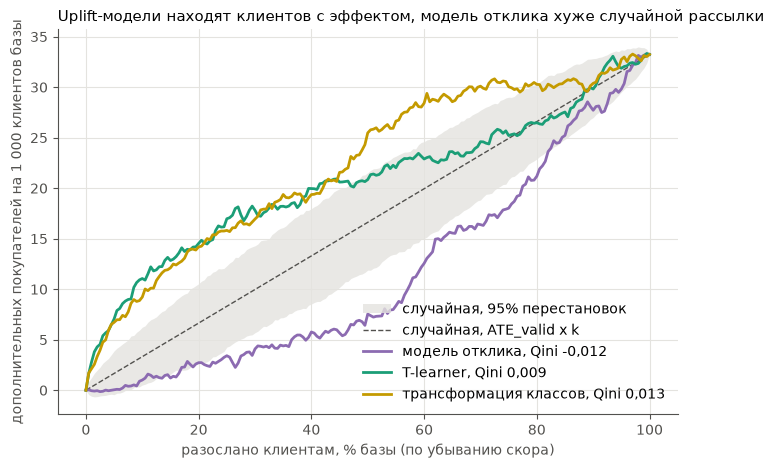

In [9]:
grid = np.linspace(0, 1, 201)
n_t_total = t.sum()


def curve_on_grid(score):
    x, q = uplift.qini_curve(y, t, score)
    return np.interp(grid, x / x[-1], q / n_t_total * 1000)


rng = np.random.default_rng(config.SEED)
perm_curves = np.array([curve_on_grid(rng.permutation(len(y))) for _ in range(1000)])
band_lo, band_hi = np.quantile(perm_curves, [0.025, 0.975], axis=0)

fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(grid * 100, band_lo, band_hi, color=plots.GRID, alpha=0.8, lw=0, label="случайная, 95% перестановок")
ax.plot([0, 100], [0, ate_valid * 1000], color=plots.INK, ls="--", lw=1, label="случайная, ATE_valid x k")
for m in MODELS:
    ax.plot(grid * 100, curve_on_grid(scores[m]), color=plots.MODEL_COLORS[m], lw=2,
            label=f"{plots.MODEL_NAMES[m]}, Qini {point.loc[m, 'qini']:.3f}".replace(".", ","))
ax.set_xlabel("разослано клиентам, % базы (по убыванию скора)")
ax.set_ylabel("дополнительных покупателей на 1 000 клиентов базы")
ax.legend(loc="lower right")
ax.set_title('Uplift-модели находят клиентов с эффектом, модель отклика хуже случайной рассылки')
plots.save(fig, "qini_valid.png")
plt.show()

Обе uplift-кривые выше коридора случайных перестановок почти на всём протяжении: T-learner чуть выше в первых
20%, трансформация классов - от 40 до 80%. Кривая модели отклика ниже коридора примерно с 10 до 85% базы:
рассылка по отклику первым делом отправляет сообщения тем, на кого оно почти не действует.

## Uplift по децилям скора

Дециль 1 - 10% клиентов с самым высоким скором. В каждом дециле - наблюдаемая разница долей покупателей
treatment - control и её 95%-интервал (нормальное приближение).

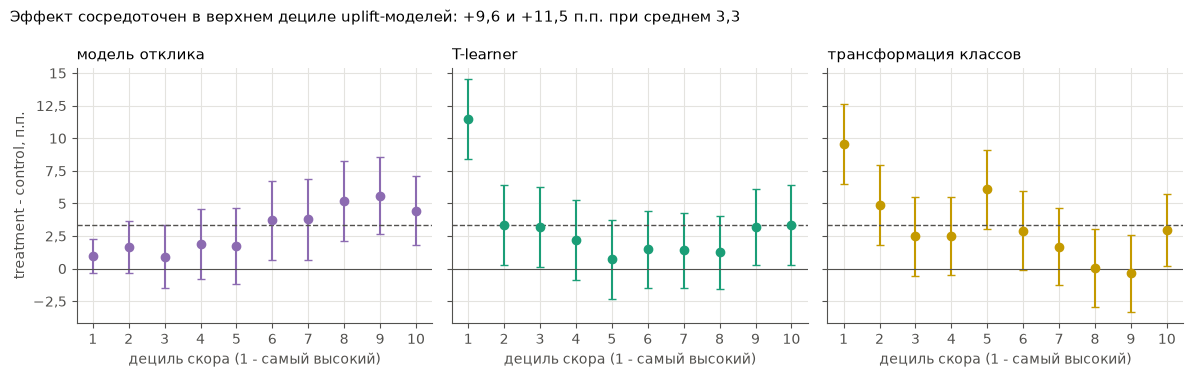

In [10]:
def by_decile(score):
    order = np.argsort(score, kind="mergesort")[::-1]
    dec = np.empty(len(score), dtype=int)
    dec[order] = np.arange(len(score)) * 10 // len(score) + 1
    df = pd.DataFrame({"decile": dec, "y": y, "t": t})
    g = df.groupby(["decile", "t"]).y.agg(["sum", "count"]).unstack("t")
    d, lo, hi = stats.diff_props_ci(g[("sum", 1)], g[("count", 1)], g[("sum", 0)], g[("count", 0)])
    return pd.DataFrame({
        "rate_treatment": g[("sum", 1)] / g[("count", 1)],
        "rate_control": g[("sum", 0)] / g[("count", 0)],
        "uplift": d, "lo": lo, "hi": hi,
        "n_treatment": g[("count", 1)], "n_control": g[("count", 0)],
    })


deciles = {m: by_decile(scores[m]) for m in MODELS}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, m in zip(axes, MODELS):
    d = deciles[m]
    ax.errorbar(d.index, d.uplift * 100, yerr=[(d.uplift - d.lo) * 100, (d.hi - d.uplift) * 100],
                fmt="o", color=plots.MODEL_COLORS[m], capsize=3)
    ax.axhline(ate_valid * 100, color=plots.INK, ls="--", lw=1)
    ax.axhline(0, color=plots.INK, lw=0.8)
    ax.set_xticks(range(1, 11))
    ax.set_xlabel("дециль скора (1 - самый высокий)")
    ax.set_title(plots.MODEL_NAMES[m])
    plots.decimal_comma(ax.yaxis)
axes[0].set_ylabel("treatment - control, п.п.")
fig.suptitle('Эффект сосредоточен в верхнем дециле uplift-моделей: +9,6 и +11,5 п.п. при среднем 3,3', x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plots.save(fig, "deciles_valid.png")
plt.show()

In [11]:
pd.concat({plots.MODEL_NAMES[m]: deciles[m][["uplift", "lo", "hi"]] * 100 for m in MODELS}, axis=1).round(2)

модель отклика             T-learner              трансформация классов             
               uplift    lo    hi    uplift    lo     hi                uplift    lo     hi
decile                                                                                     
1                0.99 -0.30  2.29     11.47  8.41  14.53                  9.58  6.52  12.64
2                1.67 -0.33  3.67      3.36  0.29   6.43                  4.86  1.78   7.93
3                0.93 -1.52  3.37      3.21  0.14   6.28                  2.48 -0.56   5.53
4                1.90 -0.80  4.60      2.21 -0.83   5.25                  2.53 -0.48   5.53
5                1.74 -1.17  4.65      0.70 -2.31   3.72                  6.08  3.06   9.09
6                3.71  0.66  6.76      1.48 -1.45   4.41                  2.91 -0.11   5.93
7                3.77  0.68  6.87      1.39 -1.48   4.27                  1.69 -1.29   4.67
8                5.19  2.11  8.26      1.25 -1.55   4.04                  0.08 -2.92   3.08
9                5.58  2.64  8.53      3.19  0.28   6.11                 -0.37 -3.32   2.57
10               4.46  1.84  7.08      3.37  0.30   6.44                  2.96  0.21   5.71

Пунктир - ATE_valid, 3,3 п.п. У обеих uplift-моделей эффект сосредоточен в верхнем дециле: +11,5 п.п.
(8,4 ... 14,5) у T-learner и +9,6 п.п. (6,5 ... 12,6) у трансформации классов. Ниже первого дециля разница
между децилями в основном в пределах шума: при 2 000 клиентов на группу в дециле интервал около ±3 п.п.
Всплеск в 5-м дециле трансформации классов (+6,1 п.п.) похож на шум. У модели отклика картина обратная:
в верхних децилях эффект около 1-2 п.п., в нижних трёх - от 4,5 до 5,6 п.п.

## Устойчивость по seed

Каждая модель обучена с выбранными параметрами на seed 42-46, Qini на valid.

In [12]:
seed_qini = pd.DataFrame({
    m: {s: uplift.qini_coef(y, t, scores_all[(m, s)].to_numpy()) for s in models.SEEDS} for m in MODELS
})
summary = seed_qini.agg(["mean", "min", "max"]).T.assign(range=lambda d: d["max"] - d["min"])
pd.concat([seed_qini.T, summary], axis=1).rename(index=plots.MODEL_NAMES).round(4)

,42,43,44,45,46,mean,min,max,range
модель отклика,-0.0121,-0.0120,-0.0121,-0.0123,-0.0120,-0.0121,-0.0123,-0.0120,0.0003
T-learner,0.0093,0.0104,0.0097,0.0105,0.0110,0.0102,0.0093,0.0110,0.0017
трансформация классов,0.0132,0.0148,0.0119,0.0128,0.0093,0.0124,0.0093,0.0148,0.0055


Средний Qini по seed: трансформация классов 0,0124 (от 0,0093 до 0,0148, размах 0,0055), T-learner 0,0102
(от 0,0093 до 0,0110, размах 0,0017). Разница средних 0,0022 меньше большего размаха 0,0055: по правилу это ничья.
Трансформация классов менее устойчива: 16 деревьев с подвыборкой сильнее зависят от seed. Модель отклика
устойчива (размах 0,0003), но устойчиво отрицательна.

## Модель отклика против uplift

Кому модель отклика и uplift-модель отправили бы сообщение. Пересечение топ-30% и доли покупателей по децилям
скора модели отклика.

In [13]:
best_uplift = summary.loc[UPLIFT_MODELS, "mean"].idxmax()
n30 = int(len(y) * 0.3)
top_resp = set(np.argsort(scores["response"], kind="mergesort")[::-1][:n30])
top_upl = set(np.argsort(scores[best_uplift], kind="mergesort")[::-1][:n30])
print(f"лучшая uplift-модель по среднему Qini: {plots.MODEL_NAMES[best_uplift]}")
print(f"общих клиентов в топ-30%: {len(top_resp & top_upl) / n30:.1%} (при случайном выборе ожидается 30%)")

лучшая uplift-модель по среднему Qini: трансформация классов
общих клиентов в топ-30%: 21.9% (при случайном выборе ожидается 30%)


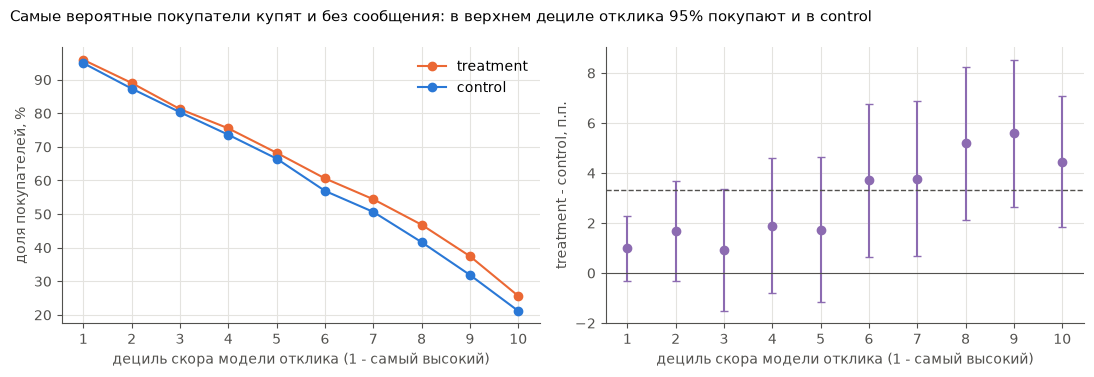

,rate_treatment,rate_control,uplift,lo,hi
decile,,,,,
1,95.92,94.92,0.99,-0.30,2.29
2,89.03,87.35,1.67,-0.33,3.67
3,81.25,80.32,0.93,-1.52,3.37
4,75.52,73.61,1.90,-0.80,4.60
5,68.24,66.50,1.74,-1.17,4.65
6,60.62,56.91,3.71,0.66,6.76
7,54.42,50.65,3.77,0.68,6.87
8,46.83,41.65,5.19,2.11,8.26
9,37.47,31.89,5.58,2.64,8.53


In [14]:
d = deciles["response"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(d.index, d.rate_treatment * 100, "o-", color=plots.GROUP_COLORS["treatment"], label="treatment")
ax1.plot(d.index, d.rate_control * 100, "o-", color=plots.GROUP_COLORS["control"], label="control")
ax1.set_xticks(range(1, 11))
ax1.set_xlabel("дециль скора модели отклика (1 - самый высокий)")
ax1.set_ylabel("доля покупателей, %")
ax1.legend()
ax2.errorbar(d.index, d.uplift * 100, yerr=[(d.uplift - d.lo) * 100, (d.hi - d.uplift) * 100],
             fmt="o", color=plots.MODEL_COLORS["response"], capsize=3)
ax2.axhline(ate_valid * 100, color=plots.INK, ls="--", lw=1)
ax2.axhline(0, color=plots.INK, lw=0.8)
ax2.set_xticks(range(1, 11))
ax2.set_xlabel("дециль скора модели отклика (1 - самый высокий)")
ax2.set_ylabel("treatment - control, п.п.")
plots.decimal_comma(ax2.yaxis)
fig.suptitle('Самые вероятные покупатели купят и без сообщения: в верхнем дециле отклика 95% покупают и в control', x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plots.save(fig, "response_deciles_valid.png")
plt.show()
(d[["rate_treatment", "rate_control", "uplift", "lo", "hi"]] * 100).round(2)

Ожидание подтвердилось. В верхнем дециле модели отклика покупают 95,9% treatment и 94,9% control: эти клиенты
купят и без сообщения, эффект +1,0 п.п. (-0,3 ... +2,3). В первых пяти децилях эффект от 0,9 до 1,9 п.п. и не
отличим от нуля, в трёх нижних - от 4,5 до 5,6 п.п. Пересечение топ-30% модели отклика и трансформации классов -
21,9%, меньше 30%, которые дал бы случайный выбор: модели отбирают почти разных клиентов.

## Выбор финальной модели

Правило из `docs/plan.md`, зафиксировано до обучения. Кандидаты - T-learner и трансформация классов, модель
отклика - бейзлайн. Выбираю подход с большим средним Qini по seed 42-46; если разница средних меньше большего
из двух размахов по seed - трансформацию классов. На test идёт модель выбранного подхода с seed 42.

In [15]:
m_t, m_ct = summary.loc["t_learner", "mean"], summary.loc["class_transformation", "mean"]
diff = m_t - m_ct
tie = abs(diff) < max(summary.loc["t_learner", "range"], summary.loc["class_transformation", "range"])
final = "class_transformation" if tie or diff < 0 else "t_learner"
print(f"средний Qini: T-learner {m_t:.4f}, трансформация классов {m_ct:.4f}, разница {diff:+.4f}")
print(f"больший размах по seed: {max(summary.loc['t_learner', 'range'], summary.loc['class_transformation', 'range']):.4f}")
print(f"ничья: {tie}; финальная модель: {plots.MODEL_NAMES[final]}, seed {config.SEED}")
print(f"модель отклика, средний Qini: {summary.loc['response', 'mean']:.4f}")

средний Qini: T-learner 0.0102, трансформация классов 0.0124, разница -0.0022
больший размах по seed: 0.0055
ничья: True; финальная модель: трансформация классов, seed 42
модель отклика, средний Qini: -0.0121


По правилу выбрана трансформация классов, seed 42 (Qini на valid 0,013). Её среднее по seed и так выше, чем
у T-learner, но разница меньше разброса по seed, поэтому решает правило ничьей, а не лучший результат.
Модель отклика финальной не становится и на valid проигрывает обеим uplift-моделям.

Вывод по valid: таргетинг по uplift-модели в топ-10% даёт около 100 дополнительных покупателей на 1 000
сообщений против 33 при случайной рассылке, а таргетинг по модели отклика - меньше случайной. Это оценки на valid,
где сравнивались подходы. На test пойдут трансформация классов с seed 42 и бейзлайны, test до сих пор не открывался.